In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from Core.Tools.histogram_accessor import HistogramAccessor

from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Input, Normalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

In [35]:
df = pd.read_csv("muon_table.csv")
df

,entry,fEventIndex,fMuonIndex,fMuonMotherPdgCode,fMuonPt,fMuonEta,fMuonPhi,fMuonSign,fMuonFwdDcaX,fMuonFwdDcaY,...,fMuonTrackTime,fMuonTrackTimeRes,fMFTIndex,fMFTPt,fMFTPhi,fMFTEta,fMFTSign,fMFTFwdDcaX,fMFTFwdDcaY,fMFTNClusters
0,0,149,0,321,0.739567,-2.948347,-3.031330,-1,-2.417705,-2.417705,...,12.487488,12.475342,2329,4.969743,-2.948349,-3.031330,1,0.0,0.0,9
1,1,149,2,-211,0.688929,-3.019638,-1.892696,-1,-10.270148,-10.270148,...,12.487488,12.475342,2345,0.083009,-3.019638,-1.892696,-1,0.0,0.0,7
2,2,149,3,211,0.451166,-3.444304,-2.972538,-1,-3.907766,-3.907766,...,12.487488,12.475342,2326,0.355247,-3.444305,-2.972538,-1,0.0,0.0,6
3,3,279,4,-2212,0.592600,-3.231277,3.065792,1,12.087129,12.087129,...,386.724270,12.475342,4454,0.144704,-3.231277,3.065792,-1,0.0,0.0,9
4,4,326,6,-211,0.373551,-3.529573,1.496347,-1,-11.300744,-11.300744,...,12.478817,12.475342,5070,0.162077,-3.529575,1.496347,-1,0.0,0.0,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35671,35671,897,57,-211,1.538544,-2.826392,-1.193903,-1,-3.618640,-3.618640,...,12.447357,12.475342,13152,0.322825,-2.826391,-1.193903,-1,0.0,0.0,8
35672,35672,908,58,-211,0.352976,-3.440341,-2.955998,-1,-4.144552,-4.144552,...,87.473404,12.475342,13335,0.356236,-3.440340,-2.955998,-1,0.0,0.0,7
35673,35673,908,60,-211,0.477040,-3.138288,-2.291882,-1,-5.739741,-5.739741,...,87.473404,12.475342,13326,0.396861,-3.138289,-2.291882,-1,0.0,0.0,6
35674,35674,908,61,-211,0.398784,-3.318035,-2.470291,-1,-4.586942,-4.586942,...,87.473404,12.475342,13298,0.415627,-3.318035,-2.470291,-1,0.0,0.0,8


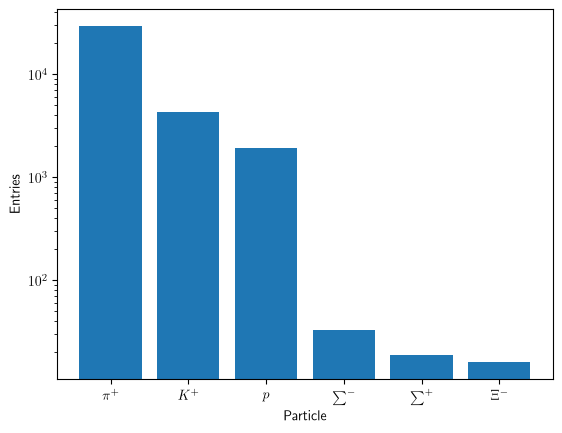

In [36]:
signals = HistogramAccessor(df, "fMuonMotherPdgCode")
signals.plot_pdgcodes()

In [37]:
df['label'] = (abs(df['fMuonMotherPdgCode'])==2212).astype(int)

In [38]:
df[['fMuonMotherPdgCode','label']]

,fMuonMotherPdgCode,label
0,321,0
1,-211,0
2,211,0
3,-2212,1
4,-211,0
...,...,...
35671,-211,0
35672,-211,0
35673,-211,0
35674,-211,0


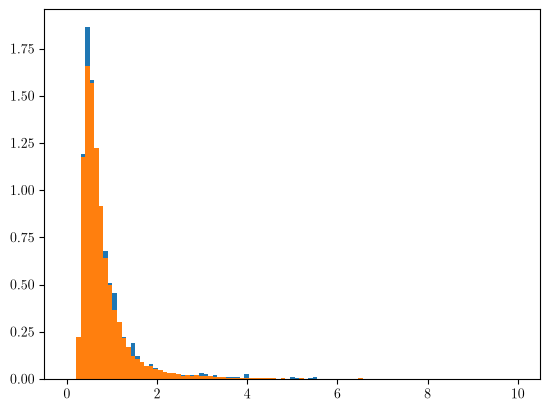

In [39]:
signal_pt = df[df['label']==1][["fMuonPt", "label"]]
signal_pt = signal_pt["fMuonPt"]

background_pt = df[df["label"] == 0][["fMuonPt", "label"]]
background_pt = background_pt["fMuonPt"]

figure, axis = plt.subplots()

pt = HistogramAccessor(df, "fMuonPt")

axis.hist(signal_pt, bins=np.linspace(0, 10, 100), density=True, label="Signal")
axis.hist(background_pt, bins=np.linspace(0, 10, 100), density=True, label="Background")

plt.show()


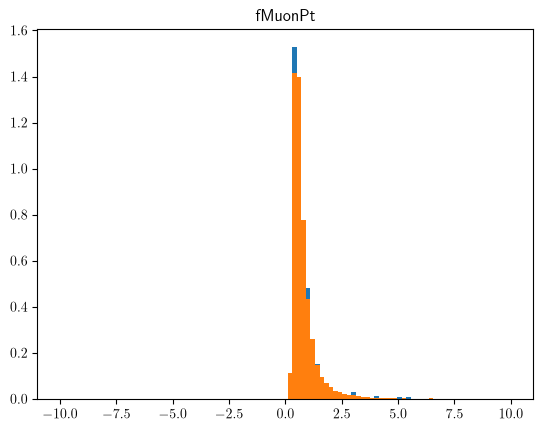

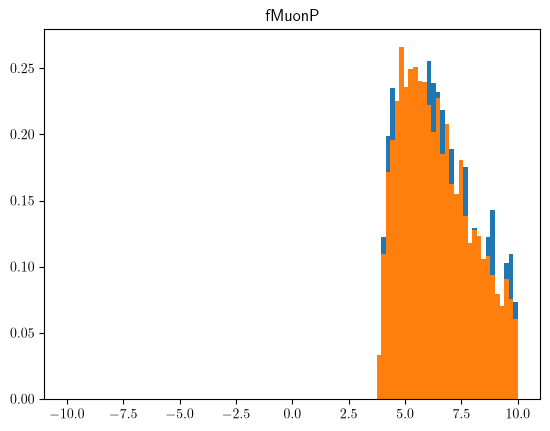

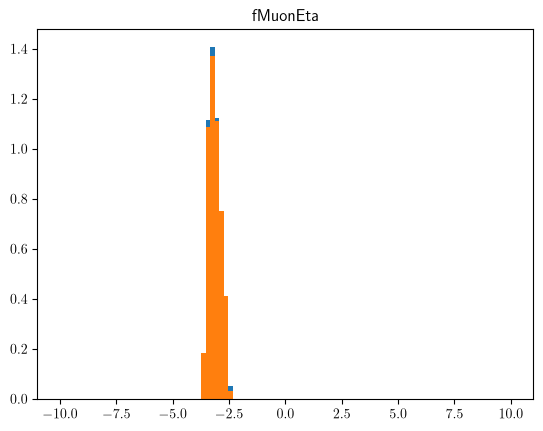

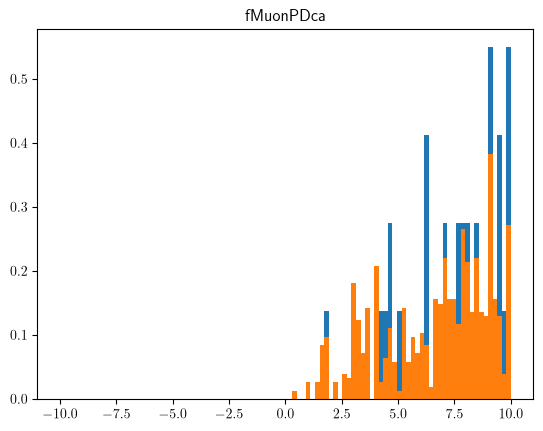

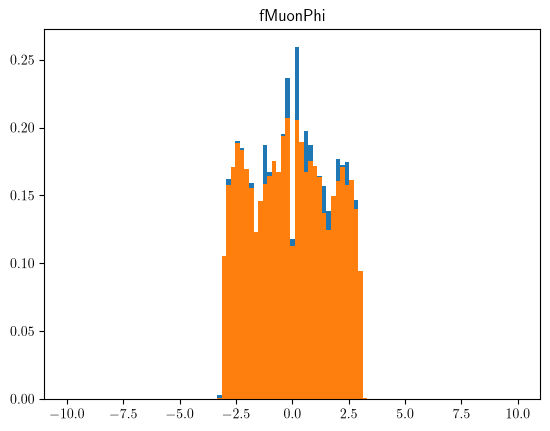

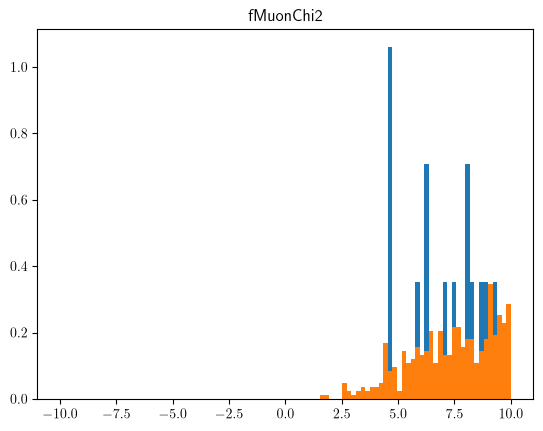

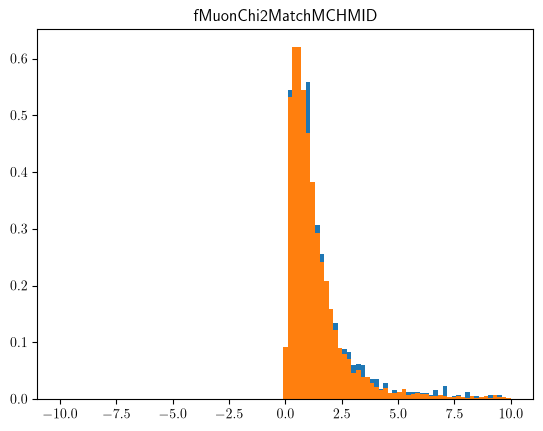

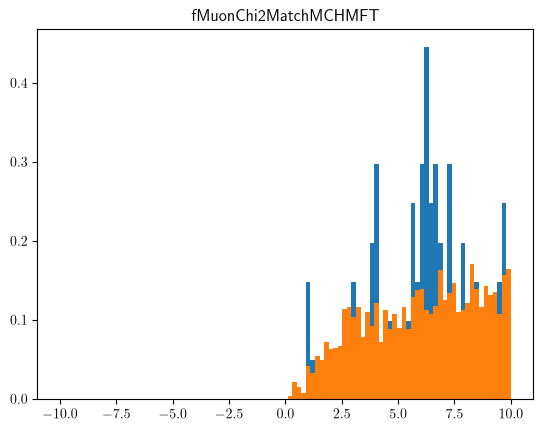

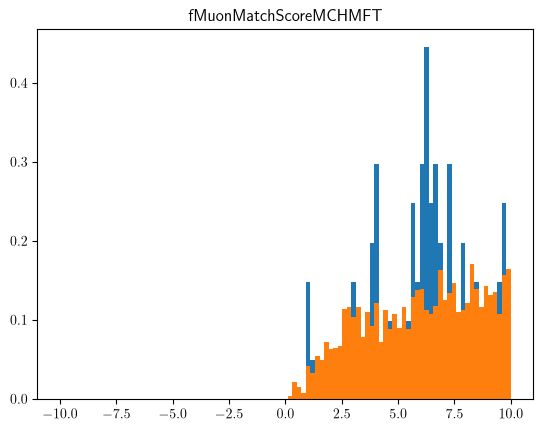

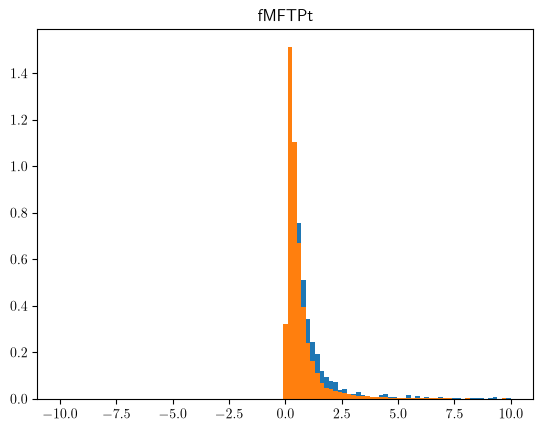

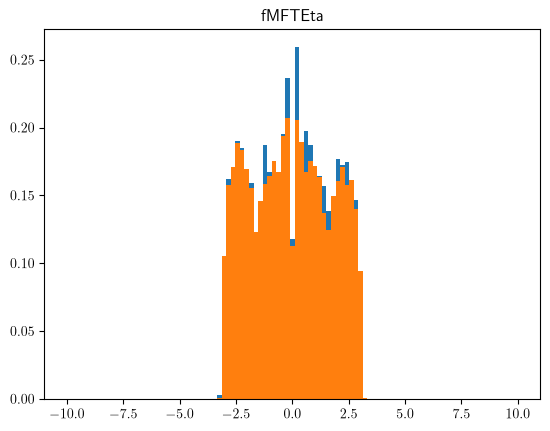

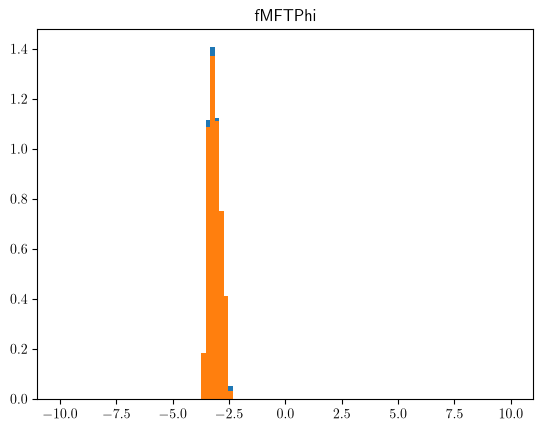

In [40]:
features = [
    "fMuonPt",
    "fMuonP",
    "fMuonEta",
    "fMuonPDca",
    "fMuonPhi",
    "fMuonChi2",
    "fMuonChi2MatchMCHMID",
    "fMuonChi2MatchMCHMFT",
    "fMuonMatchScoreMCHMFT",
    "fMFTPt",
    "fMFTEta",
    "fMFTPhi"
]


for feature in features:
    signal_pt = df[df['label']==1][[feature, "label"]]
    signal_pt = signal_pt[feature]

    background_pt = df[df["label"] == 0][[feature, "label"]]
    background_pt = background_pt[feature]

    figure, axis = plt.subplots()

    # pt = HistogramAccessor(df, "fMuonPt")

    axis.hist(signal_pt, bins=np.linspace(-10, 10, 100), density=True, label="Signal")
    axis.hist(background_pt, bins=np.linspace(-10, 10, 100), density=True, label="Background")

    plt.title(feature)
    plt.show()

In [41]:
X = df[features].values
y = df['label'].values

In [42]:
x_test, x_temp, y_test, y_temp = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

In [43]:
x_train, x_val, y_train, y_val = train_test_split(x_temp, y_temp, test_size=0.67, random_state=42, stratify=y_temp)

In [44]:
# Normalization
norm = Normalization()
norm.adapt(x_train)

In [46]:
# Build Network
model = Sequential(
    [
        norm,
        Dense(64, activation='relu'),
        Dense(32, activation='relu'),
        Dense(1, activation='sigmoid'),
    ]
)
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["AUC"])


In [48]:
model.fit(
    x_train, y_train,
    validation_data=[x_val, y_val],
    epochs = 30,
    verbose=1
)

Epoch 1/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - AUC: 0.4634 - loss: 0.3122 - val_AUC: 0.5070 - val_loss: 0.2258
Epoch 2/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - AUC: 0.5434 - loss: 0.2213 - val_AUC: 0.5209 - val_loss: 0.2200
Epoch 3/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 942us/step - AUC: 0.5516 - loss: 0.2169 - val_AUC: 0.5217 - val_loss: 0.2194
Epoch 4/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 940us/step - AUC: 0.5670 - loss: 0.2150 - val_AUC: 0.5206 - val_loss: 0.2182
Epoch 5/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - AUC: 0.5711 - loss: 0.2134 - val_AUC: 0.5208 - val_loss: 0.2186
Epoch 6/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - AUC: 0.5855 - loss: 0.2109 - val_AUC: 0.5242 - val_loss: 0.2186
Epoch 7/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - AUC: 0.5868 - loss: 0.2100 - val_AUC: 0.5203 - val_loss: 0.2178
Epoch 8/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 924us/step - AUC: 0.5974 - loss: 0.2091 - val_AUC: 0.5243 - val_loss: 0.2175
Epoch 9/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 959us/step - AUC: 0.5983 